# Phase 1 (Part A): Noise generators, GAT and statistical tests

**Project:** Robustness of classical denoising under noise-model mismatch (AWGN vs Poisson-Gaussian)

This notebook only **calls** the functions in `noise/` and `utils/`; all the logic lives in the `.py` files.
It shows that every Phase 1 deliverable of Part A works:

1. Image loading (`load_dataset`)
2. AWGN generator, with mean and std checks
3. Poisson-Gaussian generator, with mean and variance checks on flat patches
4. Forward GAT, with the variance-stabilization check
5. Algebraic and closed-form inverse GAT, with round-trip and bias checks

**Models**

$$\text{AWGN:}\quad z = x + n,\quad n\sim\mathcal N(0,\sigma^2)$$

$$\text{Poisson-Gaussian:}\quad z = \alpha\,\mathrm{Poisson}(x/\alpha) + n,\quad n\sim\mathcal N(0,\sigma^2)
\;\Rightarrow\; \mathbb E[z]=x,\;\; \mathrm{Var}(z)=\alpha x+\sigma^2$$

We describe the Poisson strength by the peak $= 1/\alpha$ (low peak = very noisy). All images are `float64` in $[0,1]$ and all $\sigma$ values are in those same units (so "$\sigma=25$" means $25/255$).

In [1]:
import sys
from pathlib import Path

# Make the repo root importable no matter where Jupyter was started
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import load_dataset, load_sample_images, load_config, make_rng
from noise import (
    add_awgn, add_poisson_gaussian, alpha_from_peak,
    gat_forward, gat_inverse_algebraic, gat_inverse_closed_form,
)
from noise.diagnostics import (
    awgn_stats, pg_flat_patch_stats, gat_flat_patch_variance, inverse_bias_curve,
)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda v: f"{v:.5g}")

cfg = load_config()
SEED = cfg["seed"]
AWGN_SIGMAS = [s / 255 for s in cfg["noise"]["awgn"]["sigmas_255"]]
PEAKS = cfg["noise"]["poisson_gaussian"]["peaks"]
print("seed:", SEED, "| AWGN sigmas (x/255):", cfg["noise"]["awgn"]["sigmas_255"], "| peaks:", PEAKS)


def show(imgs, titles=None, ncols=None, size=3.0):
    # Display images in [0, 1] (noisy images are clipped for DISPLAY only, the data is not clipped)
    n = len(imgs)
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, im in enumerate(imgs):
        axes.ravel()[i].imshow(im, cmap="gray", vmin=0, vmax=1)
        if titles:
            axes.ravel()[i].set_title(titles[i], fontsize=9)
    plt.tight_layout()
    plt.show()

seed: 2026 | AWGN sigmas (x/255): [15, 25, 50] | peaks: [1, 2, 5, 10, 30]


/home/kiranr/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Data loading

`load_dataset("set12")` reads `data/set12/*`, converts to grayscale and scales to $[0,1]$.
If the dataset folder is not there yet, we fall back to a few scikit-image sample images so the notebook still runs.

Source: Set12 | 12 images


,name,shape,dtype,min,max
0,01.png,"(256, 256)",float64,0.027451,0.99216
1,02.png,"(256, 256)",float64,0.062745,0.93725
2,03.png,"(256, 256)",float64,0,0.99608
3,04.png,"(256, 256)",float64,0.07451,0.98039
4,05.png,"(256, 256)",float64,0.062745,0.95294
5,06.png,"(256, 256)",float64,0.062745,0.90196
6,07.png,"(256, 256)",float64,0,0.99608
7,08.png,"(512, 512)",float64,0.094118,0.96078
8,09.png,"(512, 512)",float64,0.047059,0.96471
9,10.png,"(512, 512)",float64,0,1


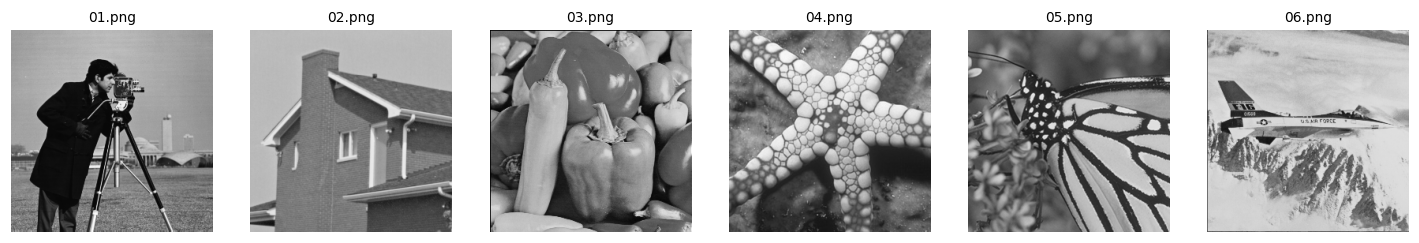

Using 01.png (256, 256)


In [2]:
try:
    images = load_dataset("set12")
    source = "Set12"
except FileNotFoundError as e:
    print("Set12 not found, using scikit-image sample images instead.\n", e)
    images = load_sample_images(256)
    source = "scikit-image samples"

print(f"Source: {source} | {len(images)} images")
rows = [(n, im.shape, im.dtype, im.min(), im.max()) for n, im in images]
display(pd.DataFrame(rows, columns=["name", "shape", "dtype", "min", "max"]))
show([im for _, im in images[:6]], [n for n, _ in images[:6]], ncols=6, size=2.2)

# the image we use for the visual examples below
name0, x0 = images[0]
print("Using", name0, x0.shape)

## 2. AWGN generator

Check: on a flat patch the noise $z-x$ should have mean $\approx 0$ and std $\approx\sigma$.

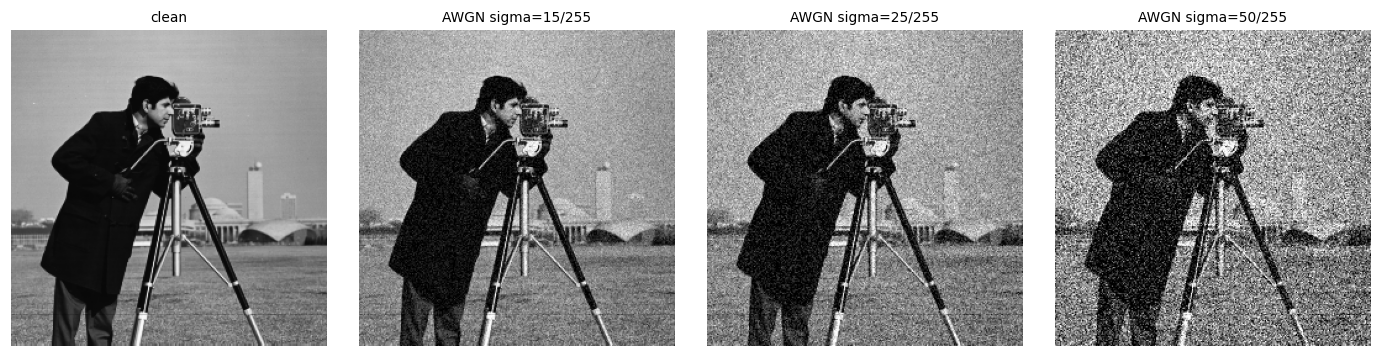

In [3]:
rng = make_rng(SEED, "nb", "awgn_visual")
show([x0] + [add_awgn(x0, s, rng) for s in AWGN_SIGMAS],
     ["clean"] + [f"AWGN sigma={round(s*255)}/255" for s in AWGN_SIGMAS], size=3.2)

,sigma (x/255),target std,empirical mean,empirical std,std rel. error %
0,15,0.058824,-0.00017753,0.058908,0.14381
1,25,0.098039,-7.5693e-05,0.097908,-0.13372
2,50,0.19608,-0.00022841,0.19601,-0.03658


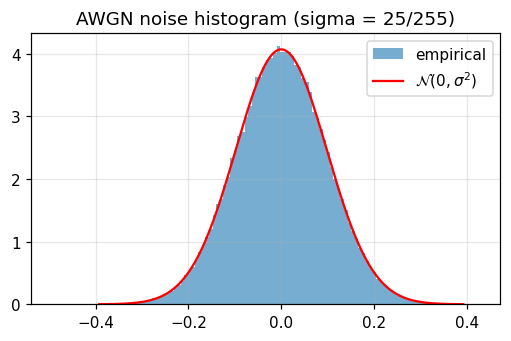

In [4]:
rows = []
for s255 in cfg["noise"]["awgn"]["sigmas_255"]:
    s = s255 / 255
    r = awgn_stats(s, make_rng(SEED, "nb", "awgn_stats", s255))
    rows.append({"sigma (x/255)": s255, "target std": s, "empirical mean": r["mean"],
                 "empirical std": r["std"], "std rel. error %": 100 * (r["std"] / s - 1)})
display(pd.DataFrame(rows))

# histogram of the noise vs the theoretical Gaussian pdf (sigma = 25/255)
s = 25 / 255
flat = np.full((512, 512), 0.5)
n = add_awgn(flat, s, make_rng(SEED, "nb", "hist")) - flat
t = np.linspace(-4 * s, 4 * s, 400)
plt.figure(figsize=(5.5, 3.2))
plt.hist(n.ravel(), bins=120, density=True, alpha=0.6, label="empirical")
plt.plot(t, np.exp(-t**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi)), "r", label=r"$\mathcal{N}(0,\sigma^2)$")
plt.title("AWGN noise histogram (sigma = 25/255)"); plt.legend(); plt.show()

## 3. Poisson-Gaussian generator

With $\alpha = 1/\text{peak}$, a lower peak means fewer photons and more noise. The noise images (bottom row) show the key difference from AWGN: **bright regions are noisier than dark ones**.

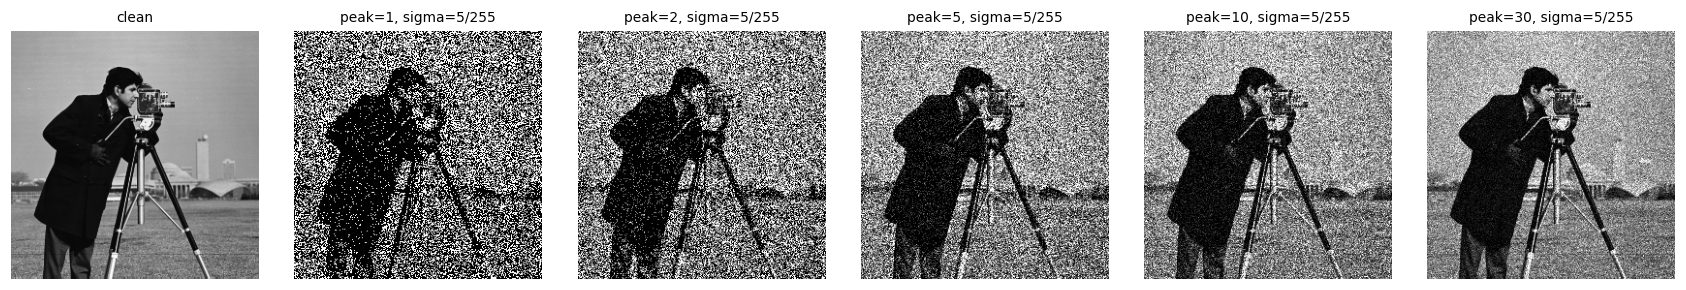

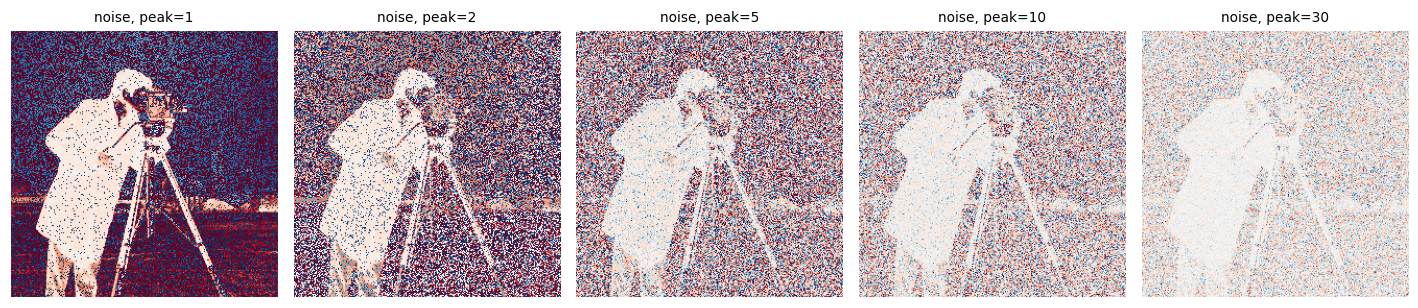

In [5]:
SIGMA_PG = 5 / 255
rng = make_rng(SEED, "nb", "pg_visual")
noisy = [add_poisson_gaussian(x0, alpha_from_peak(p), SIGMA_PG, rng) for p in PEAKS]
show([x0] + noisy, ["clean"] + [f"peak={p}, sigma=5/255" for p in PEAKS], size=2.6)

# noise maps z - x, same colour scale for all panels
fig, axes = plt.subplots(1, len(PEAKS), figsize=(2.6 * len(PEAKS), 2.8))
for ax, z, p in zip(axes, noisy, PEAKS):
    ax.imshow(z - x0, cmap="RdBu", vmin=-0.5, vmax=0.5); ax.axis("off"); ax.set_title(f"noise, peak={p}", fontsize=9)
plt.tight_layout(); plt.show()

### Flat-patch test: $\mathbb E[z]\approx x$ and $\mathrm{Var}(z)\approx \alpha x+\sigma^2$

In [6]:
rows = []
for p in [1, 5, 30]:
    for s255 in [0, 10]:
        for xv in [0.1, 0.5, 0.9]:
            r = pg_flat_patch_stats(xv, alpha_from_peak(p), s255 / 255, make_rng(SEED, "nb", "pgflat", p, s255, int(xv * 10)))
            rows.append({"peak": p, "sigma (x/255)": s255, "x": xv, "mean": r["mean"],
                         "var": r["var"], "var theory": r["var_theory"],
                         "var rel. err %": 100 * (r["var"] / r["var_theory"] - 1)})
df = pd.DataFrame(rows)
display(df)
print("max |mean - x|          :", float(np.max(np.abs(df["mean"] - df["x"]))))
print("max |var rel. error| %  :", float(np.max(np.abs(df["var rel. err %"]))))

,peak,sigma (x/255),x,mean,var,var theory,var rel. err %
0,1,0,0.1,0.10036,0.10028,0.1,0.28307
1,1,0,0.5,0.50182,0.50301,0.5,0.60206
2,1,0,0.9,0.90009,0.89391,0.9,-0.67671
3,1,10,0.1,0.1006,0.103,0.10154,1.438
4,1,10,0.5,0.50042,0.5016,0.50154,0.013147
5,1,10,0.9,0.90151,0.90189,0.90154,0.038889
6,5,0,0.1,0.10045,0.020102,0.02,0.5117
7,5,0,0.5,0.50069,0.099908,0.1,-0.092024
8,5,0,0.9,0.90158,0.18032,0.18,0.17748
9,5,10,0.1,0.099786,0.021528,0.021538,-0.043986


max |mean - x|          : 0.00182342529296875
max |var rel. error| %  : 1.4380248722156708


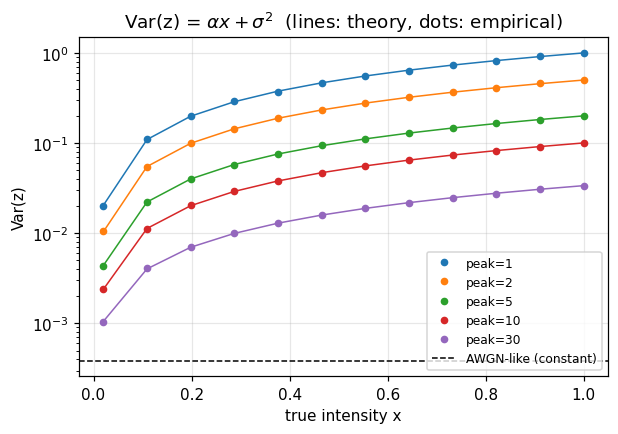

In [7]:
# variance vs intensity: theory line alpha*x + sigma^2 and empirical dots, for each peak
xs = np.linspace(0.02, 1.0, 12)
sigma = 5 / 255
plt.figure(figsize=(6.2, 4))
for p in PEAKS:
    a = alpha_from_peak(p)
    emp = [pg_flat_patch_stats(xv, a, sigma, make_rng(SEED, "nb", "varcurve", p, i), shape=(256, 256))["var"] for i, xv in enumerate(xs)]
    line, = plt.plot(xs, a * xs + sigma**2, "-", lw=1)
    plt.plot(xs, emp, "o", ms=4, color=line.get_color(), label=f"peak={p}")
plt.axhline(sigma**2, color="k", ls="--", lw=1, label="AWGN-like (constant)")
plt.yscale("log"); plt.xlabel("true intensity x"); plt.ylabel("Var(z)")
plt.title(r"Var(z) = $\alpha x + \sigma^2$  (lines: theory, dots: empirical)")
plt.legend(fontsize=8); plt.show()

### Why this matters for the project: AWGN noise is flat, Poisson-Gaussian noise is not

On a real image, measure the noise std in intensity bins. For a fair comparison, the AWGN $\sigma$ is chosen so both noises have the **same overall noise power**. A denoiser that assumes one global $\sigma$ is therefore "right on average" but wrong in dark and bright areas; that is the mismatch we study.

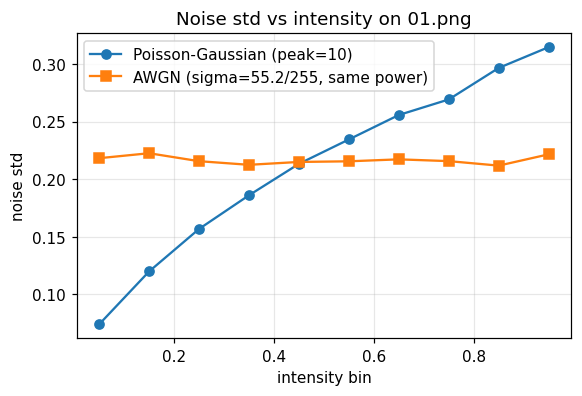

In [8]:
def binned_noise_std(x, z, nbins=10):
    edges = np.linspace(0, 1, nbins + 1)
    idx = np.clip(np.digitize(x.ravel(), edges) - 1, 0, nbins - 1)
    n = (z - x).ravel()
    centers = (edges[:-1] + edges[1:]) / 2
    std = np.array([n[idx == b].std() if (idx == b).sum() > 50 else np.nan for b in range(nbins)])
    return centers, std

peak, sigma = 10, 5 / 255
a = alpha_from_peak(peak)
rng = make_rng(SEED, "nb", "binned")
z_pg = add_poisson_gaussian(x0, a, sigma, rng)
sigma_eq = np.sqrt(np.mean(a * x0 + sigma**2))           # same average noise power
z_aw = add_awgn(x0, sigma_eq, rng)

c, s_pg = binned_noise_std(x0, z_pg)
_, s_aw = binned_noise_std(x0, z_aw)
plt.figure(figsize=(5.8, 3.6))
plt.plot(c, s_pg, "o-", label=f"Poisson-Gaussian (peak={peak})")
plt.plot(c, s_aw, "s-", label=f"AWGN (sigma={sigma_eq*255:.1f}/255, same power)")
plt.xlabel("intensity bin"); plt.ylabel("noise std"); plt.title(f"Noise std vs intensity on {name0}"); plt.legend(); plt.show()

## 4. Forward GAT

$$f(z)=\frac{2}{\alpha}\sqrt{\alpha z+\tfrac38\alpha^2+\sigma^2}$$

Goal: after the transform the noise is approximately $\mathcal N(0,1)$ with **constant variance 1**, independent of the intensity. This is what lets us use Gaussian-oriented denoisers on Poisson-Gaussian data.

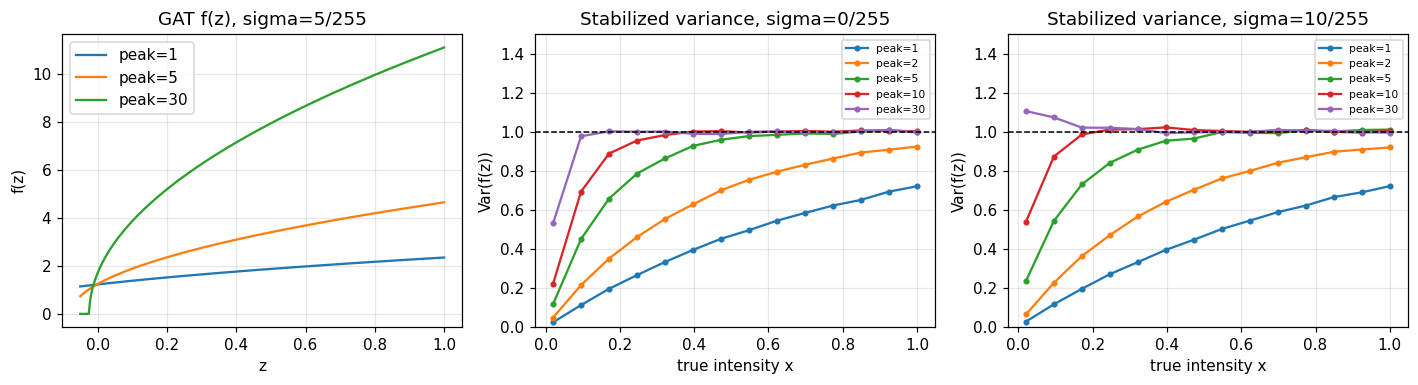

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# (a) the transform itself
zz = np.linspace(-0.05, 1.0, 300)
for p in [1, 5, 30]:
    axes[0].plot(zz, gat_forward(zz, alpha_from_peak(p), 5 / 255), label=f"peak={p}")
axes[0].set_title("GAT f(z), sigma=5/255"); axes[0].set_xlabel("z"); axes[0].set_ylabel("f(z)"); axes[0].legend()

# (b), (c) stabilized variance on flat patches, for two read-noise levels
xs = np.linspace(0.02, 1.0, 14)
for ax, s255 in zip(axes[1:], [0, 10]):
    for p in PEAKS:
        v = [gat_flat_patch_variance(xv, alpha_from_peak(p), s255 / 255, make_rng(SEED, "nb", "gatvar", p, s255, i), shape=(256, 256))
             for i, xv in enumerate(xs)]
        ax.plot(xs, v, "o-", ms=3, label=f"peak={p}")
    ax.axhline(1, color="k", ls="--", lw=1)
    ax.set_ylim(0, 1.5); ax.set_xlabel("true intensity x"); ax.set_ylabel("Var(f(z))")
    ax.set_title(f"Stabilized variance, sigma={s255}/255"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading the plot:** the variance is close to 1 once the expected photon count \cdot\text{peak}$ is roughly $ or more (a larger read noise $\sigma$ helps a little at the dark end). Below that (low peak and/or dark pixels) the GAT cannot stabilize perfectly and the variance drops below 1. This is a known limit of the transform, not a bug, and it is part of what we expect to see when VST-mediated pipelines are run at the extreme noise levels.

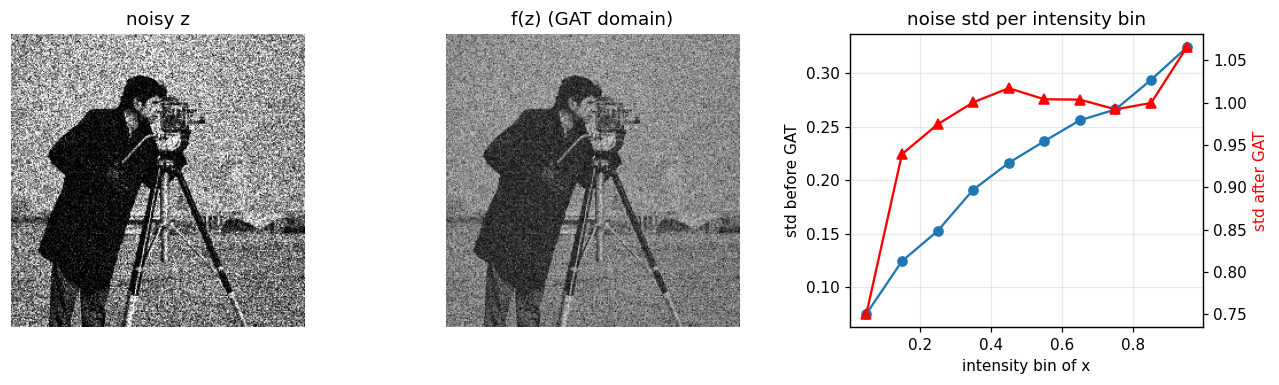

In [10]:
# the transform applied to an image: noise becomes uniform across intensities
p, s255 = 10, 5
a, sg = alpha_from_peak(p), s255 / 255
z = add_poisson_gaussian(x0, a, sg, make_rng(SEED, "nb", "gat_img"))
f = gat_forward(z, a, sg)
fx = gat_forward(x0, a, sg)    # GAT of the clean image: rough noise-free reference in the GAT domain
c, s_before = binned_noise_std(x0, z)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].imshow(z, cmap="gray", vmin=0, vmax=1); axes[0].set_title("noisy z"); axes[0].axis("off")
axes[1].imshow(f, cmap="gray"); axes[1].set_title("f(z) (GAT domain)"); axes[1].axis("off")
axes[2].plot(c, s_before, "o-", label="std of z - x")
# std of f(z) - f(x) per intensity bin of x
idx = np.clip(np.digitize(x0.ravel(), np.linspace(0, 1, 11)) - 1, 0, 9)
d = (f - fx).ravel()
axes[2].set_xlabel("intensity bin of x")
ax2 = axes[2].twinx()
ax2.plot(c, [d[idx == b].std() if (idx == b).sum() > 50 else np.nan for b in range(10)], "r^-", label="std of f(z) - f(x)")
axes[2].set_ylabel("std before GAT"); ax2.set_ylabel("std after GAT", color="r"); ax2.grid(False)
axes[2].set_title("noise std per intensity bin")
plt.tight_layout(); plt.show()

## 5. Inverse GAT

After denoising in the GAT domain we must map back. Two inverses are implemented now:

* **Algebraic:** solve $f(z)=\hat f$ for $z$. Exact for a plain round trip, but **biased** for denoised values at low counts, because $\mathbb E[f(z)]\neq f(\mathbb E[z])$.
* **Closed-form approximation of the exact unbiased inverse** (Makitalo and Foi): designed so that applying it to $\mathbb E[f(z)]$ returns $x$.

(The exact unbiased inverse is the Phase 2 stretch goal; `gat_inverse_exact_unbiased` is a stub for now.)

### 5a. Round-trip test (algebraic)

In [11]:
a, sg = alpha_from_peak(10), 5 / 255
z = add_poisson_gaussian(x0, a, sg, make_rng(SEED, "nb", "roundtrip"))
valid = a * z + 0.375 * a**2 + sg**2 > 0          # pixels where the sqrt argument was positive
z_back = gat_inverse_algebraic(gat_forward(z, a, sg), a, sg)
print("max |inverse(forward(z)) - z| on valid pixels:", float(np.max(np.abs(z_back - z)[valid])))
print("pixels where z was too negative for the sqrt (floored at 0):", int((~valid).sum()), "of", z.size)

max |inverse(forward(z)) - z| on valid pixels: 6.661338147750939e-16
pixels where z was too negative for the sqrt (floored at 0): 138 of 65536


### 5b. Bias test: apply the inverse to $\mathbb E[f(z)]$

For each true value $x$ we draw many noisy samples, average their GAT values (this mimics an *ideal* denoiser output in the GAT domain), and apply each inverse. An unbiased inverse returns $x$, so points should lie on the diagonal. Here $\alpha=1$, so $x$ is in photon counts.

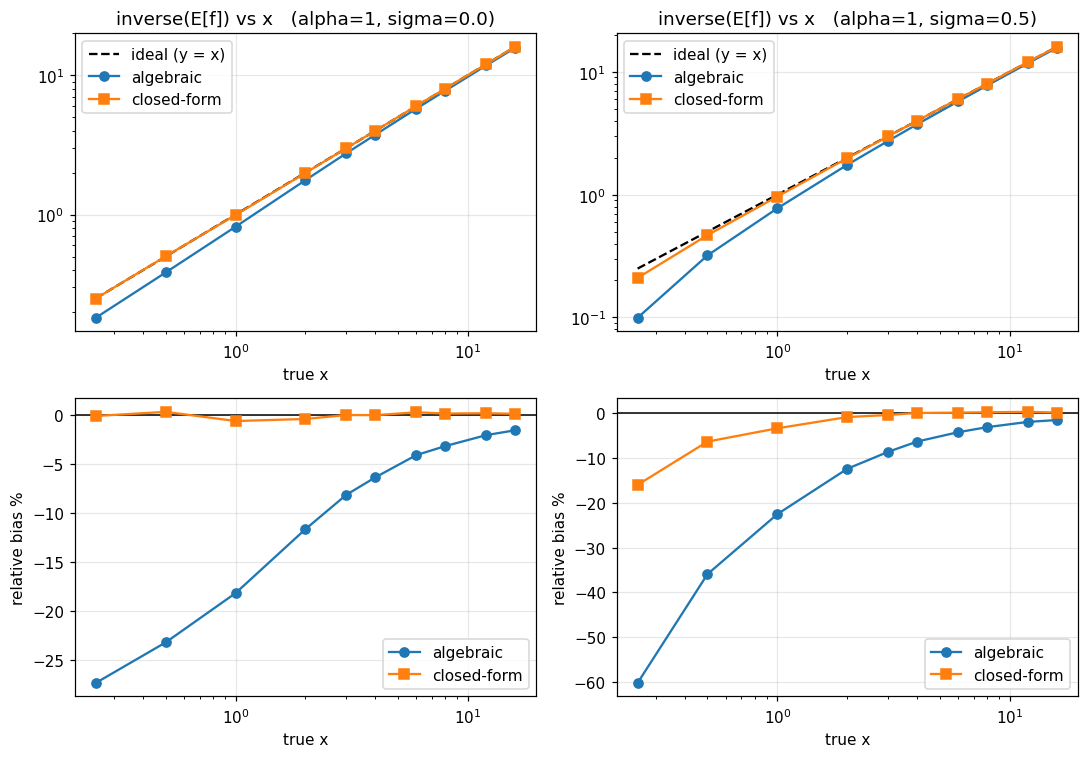

In [12]:
xs = np.array([0.25, 0.5, 1, 2, 3, 4, 6, 8, 12, 16])
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for col, sg in enumerate([0.0, 0.5]):
    res = inverse_bias_curve(xs, alpha=1.0, sigma=sg, rng=make_rng(SEED, "nb", "bias", int(sg * 10)), n_samples=300_000)
    ax = axes[0, col]
    ax.plot(xs, xs, "k--", label="ideal (y = x)")
    ax.plot(xs, res["algebraic"], "o-", label="algebraic")
    ax.plot(xs, res["closed_form"], "s-", label="closed-form")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"inverse(E[f]) vs x   (alpha=1, sigma={sg})")
    ax.set_xlabel("true x"); ax.legend()
    ax = axes[1, col]
    ax.axhline(0, color="k", lw=1)
    ax.plot(xs, 100 * (res["algebraic"] - xs) / xs, "o-", label="algebraic")
    ax.plot(xs, 100 * (res["closed_form"] - xs) / xs, "s-", label="closed-form")
    ax.set_xscale("log"); ax.set_xlabel("true x"); ax.set_ylabel("relative bias %"); ax.legend()
plt.tight_layout(); plt.show()

**Reading the plot:** the algebraic inverse under-estimates, strongly at low counts. The closed-form inverse stays close to the diagonal across the whole range. This is the reason the VST pipeline in Phase 2 will use the closed-form inverse (or the exact unbiased one if we reach the stretch goal).

## 6. Run the automated tests

The same checks (with pass/fail thresholds) are in `tests/`. Running them here keeps the evidence in one place.

In [13]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "-v", "--tb=short"], cwd=ROOT, capture_output=True, text=True)
lines = out.stdout.strip().splitlines()
print("\n".join(lines[-40:]))

============================= test session starts ==============================
platform linux -- Python 3.10.12, pytest-8.3.4, pluggy-1.5.0
rootdir: /home/kiranr/Documents/4-1/DIP/project/denoising-mismatch-phase1/denoising-mismatch
configfile: pytest.ini
testpaths: tests
plugins: anyio-4.3.0, xdist-3.8.0
collected 65 items

tests/test_data_loader.py .....                                          [  7%]
tests/test_gat.py .....................                                  [ 40%]
tests/test_noise_stats.py .......................................        [100%]

============================== 65 passed in 1.12s ==============================


## 7. Phase 1 (Part A) status

| Deliverable | Where | Status |
|---|---|---|
| Image loading to float64 in $[0,1]$, grayscale | `utils/data_loader.py` | done |
| AWGN generator + mean/std test | `noise/awgn.py`, `tests/test_noise_stats.py` | done |
| Poisson-Gaussian generator + clipping policy + mean/variance test | `noise/poisson_gaussian.py` | done |
| Forward GAT + stabilized-variance test | `noise/gat.py`, `tests/test_gat.py` | done |
| Algebraic inverse + round-trip test | `noise/gat.py` | done |
| Closed-form unbiased-inverse approximation + bias test | `noise/gat.py` | done |
| Exact unbiased inverse | `noise/gat.py` | Phase 2 stretch (stub) |

**Clipping policy (documented):** noise is **not** clipped by default (`clip=False`), so $\mathbb E[z]=x$ and the GAT theory hold exactly. `clip=True` clips to $[0,1]$ if we later want an 8-bit sensor model. Phase 2 can run a small clipped vs unclipped ablation.

**Still to check against the reference:** compare `gat_inverse_closed_form` with the MATLAB routine `GenAnscombe_inverse_closed_form.m` on a few inputs (MATLAB/Octave needed; not available when this notebook was written).